# 02 · 建立 longitudinal 資料集

**怎麼把 sensor stream 變成「不偷看未來」的訓練樣本？**

```
sensor parquet（每 4 秒一筆）+ episodes（01 定義）
   ↓ 1. 每 5 分鐘聚合成一個窗
   ↓ 2. 用日曆截止日切成 train / val / test
   ↓ 3. 每個窗 = 一個預測時間點 t，標籤 = 從 t 到下一次事故的時間與類型
   ↓ 4. 加上 t 當下已知的事故歷史
   ↓ 5. 抽樣
   ↓ 6. 洩漏檢查
windows.parquet（sensor 特徵）+ landmarks.parquet（標籤、事故歷史、split）
```

原則：在時間 t 的預測，只能用 t 以前的資料。

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

BASE_DIR = os.path.abspath("..")
PROCESSED_DIR = os.path.join(BASE_DIR, "data/processed")
SENSOR_DIR = os.path.join(PROCESSED_DIR, "sensor")
# 圖表存在 data_prep/figures/02_build_dataset/
OUT_DIR = os.path.join(BASE_DIR, "data_prep", "figures", "02_build_dataset")
os.makedirs(OUT_DIR, exist_ok=True)
print("結果會存在：", OUT_DIR)

FAULT_COLORS = {"low": "#2a78d6", "high": "#eb6834", "leak": "#1baf7a"}
EVENT_CODE = {"censored": 0, "low": 1, "high": 2, "leak": 3}

# ----- 時間窗（01 第 2、8 節）-----
WINDOW_S = 300                     # 5 分鐘
CONT = [                           # 連續的製程訊號：取 mean / std / min / max
    "IONGAUGEPRESSURE", "ETCHBEAMVOLTAGE", "ETCHBEAMCURRENT",
    "ETCHSUPPRESSORVOLTAGE", "ETCHSUPPRESSORCURRENT", "FLOWCOOLFLOWRATE",
    "FLOWCOOLPRESSURE", "ETCHGASCHANNEL1READBACK", "ETCHPBNGASREADBACK",
    "ACTUALROTATIONANGLE", "ACTUALSTEPDURATION",
]
LAST = ["FLOWCOOLFLOWRATE", "FLOWCOOLPRESSURE"]    # 三種故障都是 Flowcool，另外保留窗內最後一筆
COUNTERS = ["ETCHSOURCEUSAGE", "ETCHAUXSOURCETIMER", "ETCHAUX2SOURCETIMER"]  # 耗材計數器：取最後一筆

# ----- 標籤（01 第 4 節）-----
HORIZON_H = 168                    # 預測範圍 7 天
EDGES_H = np.array([0, 0.5, 1, 2, 4, 6, 9, 12, 18, 24, 36, 48, 72, 96, 120, 144, 168])   # 16 個時間格

# ----- 切分與抽樣 -----
SPLIT_Q = (0.60, 0.75)             # 前 60% 的事故 -> train，60~75% -> val，之後 -> test
SAMPLE_FRAC = 0.08
SEED = 42

結果會存在： data_prep/figures/02_build_dataset


In [2]:
ep = pd.read_parquet(os.path.join(PROCESSED_DIR, "episodes.parquet"))
tools = sorted(ep.tool.unique())
print(len(ep), "個 episode")
ep.head()

1067 個 episode


,episode_id,tool,start,end,event,n_alarms,hours
0,01M01_000,01M01,3283106,6533184,low,1,902.799444
1,01M01_001,01M01,6533188,8286500,low,1,487.031111
2,01M01_002,01M01,8286504,8627086,low,1,94.606111
3,01M01_003,01M01,8627090,8697340,low,1,19.513889
4,01M01_004,01M01,8697342,8971484,low,1,76.150556


## 1. 5 分鐘時間窗

| 特徵 | 內容 |
|---|---|
| 製程訊號（11 個） | mean / std / min / max |
| Flowcool 流量、壓力 | 窗內最後一筆 |
| 耗材計數器（3 個） | 窗內最後一筆 |
| 其他 | 窗內筆數、run 數、與上一個窗的間隔 |

**先把每筆資料指派到所屬的 episode，再聚合**：故障當下和之後的資料不算，所以一個窗不會同時包含故障前和故障後的資料。

In [3]:
agg = {"time": ["min", "max", "size"], "runnum": "nunique"}
for c in CONT:
    agg[c] = ["mean", "std", "min", "max"]
for c in LAST + COUNTERS:
    agg[c] = agg.get(c, []) + ["last"]

windows = []
for tool in tools:
    s = pd.read_parquet(os.path.join(SENSOR_DIR, f"{tool}.parquet"))
    s = s.drop_duplicates().sort_values("time", kind="stable")       # 01：完全重複的列去掉（要用整列比對）

    # 每筆資料屬於哪個 episode
    e = ep[ep.tool == tool].sort_values("start")
    i = np.searchsorted(e.start.to_numpy(), s.time.to_numpy(), side="right") - 1
    ok = i >= 0
    i = i.clip(0)
    end, event = e.end.to_numpy()[i], e.event.to_numpy()[i]
    ok &= (s.time.to_numpy() < end) | ((event == "censored") & (s.time.to_numpy() <= end))
    s = s[ok].assign(episode_id=e.episode_id.to_numpy()[i[ok]])

    s["win"] = s.time // WINDOW_S
    w = s.groupby(["episode_id", "win"]).agg(agg)
    w.columns = [f"{c.lower()}_{f}" for c, f in w.columns]
    windows.append(w.reset_index().assign(tool=tool))

windows = pd.concat(windows, ignore_index=True).rename(columns={
    "time_min": "t_first", "time_max": "t_last", "time_size": "n_rows", "runnum_nunique": "n_runs"})

# 只有 1 筆的窗算不出 std -> 0
std_cols = [c for c in windows.columns if c.endswith("_std")]
windows[std_cols] = windows[std_cols].fillna(0)

# 每個 episode 內：第幾個窗、與上一個窗隔幾秒
windows = windows.sort_values(["episode_id", "win"]).reset_index(drop=True)
windows["win_idx"] = windows.groupby("episode_id").cumcount()
windows["gap_s"] = windows.groupby("episode_id").t_last.diff().fillna(0)

print(windows.shape)
windows.head()

(1295233, 58)


,episode_id,win,t_first,t_last,n_rows,n_runs,iongaugepressure_mean,iongaugepressure_std,iongaugepressure_min,iongaugepressure_max,etchbeamvoltage_mean,etchbeamvoltage_std,etchbeamvoltage_min,etchbeamvoltage_max,etchbeamcurrent_mean,...,etchpbngasreadback_max,actualrotationangle_mean,actualrotationangle_std,actualrotationangle_min,actualrotationangle_max,actualstepduration_mean,actualstepduration_std,actualstepduration_min,actualstepduration_max,etchsourceusage_last,etchauxsourcetimer_last,etchaux2sourcetimer_last,tool,win_idx,gap_s
0,01M01_000,10943,3283106,3283198,24,1,-1.069084,0.493669,-1.332175,0.745235,-1.027096,0.451662,-1.128402,1.085043,-1.151861,...,0.727147,-0.152495,0.0,-0.152495,-0.152495,-0.200587,0.000000,-0.200587,-0.200587,-0.071733,-0.257798,0.862781,01M01,0,0.0
1,01M01_000,10944,3283202,3283498,47,1,-1.030471,0.744486,-1.354529,1.080309,-0.971716,0.362744,-1.128402,0.441242,-1.044793,...,2.267026,-0.152495,0.0,-0.152495,-0.152495,-0.200587,0.000000,-0.200587,-0.200587,-0.071700,-0.257771,0.862829,01M01,1,300.0
2,01M01_000,10945,3283502,3283798,75,1,0.501303,0.047364,0.491432,0.824571,-0.184915,0.000242,-0.185334,-0.184506,0.064430,...,0.758704,-0.152495,0.0,-0.152495,-0.152495,-0.200587,0.000000,-0.200587,-0.200587,-0.071298,-0.257432,0.863439,01M01,2,300.0
3,01M01_000,10946,3283802,3284026,57,1,-0.844418,0.764308,-1.348422,0.491432,-0.909161,0.399457,-1.128402,-0.149296,-0.894757,...,0.738951,-0.152495,0.0,-0.152495,-0.152495,-0.281798,0.040066,-0.301218,-0.200587,-0.071226,-0.257376,0.863540,01M01,3,228.0
4,01M01_000,10947,3284138,3284398,66,1,-0.029692,0.865484,-1.354338,1.043911,-0.465044,0.439020,-1.128402,0.448765,-0.328311,...,0.775974,-0.152495,0.0,-0.152495,-0.152495,-0.301218,0.000000,-0.301218,-0.301218,-0.070981,-0.257172,0.863908,01M01,4,372.0


In [4]:
SEQ_COLS = [c for c in windows.columns if c not in ["episode_id", "win", "tool", "t_first", "t_last", "win_idx"]]
print(len(SEQ_COLS), "個 sensor 特徵")
print("有缺值的欄位：", windows[SEQ_COLS].columns[windows[SEQ_COLS].isna().any()].tolist())

52 個 sensor 特徵
有缺值的欄位： []


## 2. 時間切分

01 第 7 節：相鄰兩個預測時間點的輸入歷史幾乎完全重疊，而且指向同一次故障，所以**不能隨機切分**。

改用所有機台共用的**日曆截止日**：依事故發生時間，前 60% → train，60%～75% → val，之後 → test。這也是實際部署的情境：用同一批機台的過去，預測它們的未來。

In [5]:
inc_time = np.sort(ep.loc[ep.event != "censored", "end"].to_numpy())
C_VAL, C_TEST = [int(np.quantile(inc_time, q)) for q in SPLIT_Q]
T0 = windows.t_first.min()
print(f"C_VAL = 第 {(C_VAL - T0) / 86400:.0f} 天，C_TEST = 第 {(C_TEST - T0) / 86400:.0f} 天")

lm = windows[["tool", "episode_id", "win", "win_idx", "t_last"]].rename(columns={"t_last": "t"})
lm = lm.merge(ep[["episode_id", "start", "end", "event"]].rename(
    columns={"start": "ep_start", "end": "ep_end", "event": "ep_event"}), on="episode_id")
lm["split"] = np.select([lm.t <= C_VAL, lm.t <= C_TEST], ["train", "val"], "test")
lm.split.value_counts()

C_VAL = 第 257 天，C_TEST = 第 326 天


split
train    772298
test     330026
val      192909
Name: count, dtype: int64

## 3. 標籤：只用截止日以前已經知道的結果

每個窗的結束時間 t 就是一個預測時間點，標籤 = **從 t 到下一次事故的時間（residual）與類型**。

切分之後還有一個容易漏掉的洩漏：train 期間最後一個 episode，可能在 C_VAL **之後**才出事。如果 train 的標籤寫「X 小時後壓力過低」，等於用了截止日之後才知道的資訊。所以：

| 資料集 | 預測時間點 | 標籤可以看到的時間 |
|---|---|---|
| train | t ≤ C_VAL | 到 C_VAL 為止；當時還沒出事的 episode → 在 C_VAL 截尾 |
| val | C_VAL < t ≤ C_TEST | 到 C_TEST 為止 |
| test | t > C_TEST | 完整標籤 |

接著把 residual 切成 16 個時間格（越接近故障切得越細），超過 7 天的 → 截尾。

In [6]:
known_until = lm.split.map({"train": C_VAL, "val": C_TEST, "test": np.iinfo(np.int64).max})
seen = lm.ep_end <= known_until                        # 這個 episode 的結局，在截止日前已經知道了嗎？
label_end = np.where(seen, lm.ep_end, known_until)
label_event = np.where(seen, lm.ep_event.map(EVENT_CODE), 0)

lm["residual_h"] = (label_end - lm.t) / 3600
lm["event"] = np.where(lm.residual_h > HORIZON_H, 0, label_event)    # 7 天後才出事 = 7 天內沒出事

In [7]:
def to_time_idx(residual_h, event):
    """residual -> 第幾個時間格（給 DeepHit 用）

    - 事故落在 (e_j, e_{j+1}]         -> j
    - 截尾落在 (e_j, e_{j+1}]         -> j - 1（只確定撐過了前一格）
      截尾在第一格內 -> -1：沒有任何資訊，之後丟掉
    - 超過 7 天                        -> 最後一格（撐過了整整 7 天）
    """
    idx_event = np.searchsorted(EDGES_H, residual_h, side="left") - 1
    idx_cens = np.searchsorted(EDGES_H, residual_h, side="right") - 2
    idx = np.where(event > 0, idx_event, idx_cens)
    return np.minimum(idx, len(EDGES_H) - 2)

lm["time_idx"] = to_time_idx(lm.residual_h.to_numpy(), lm.event.to_numpy())
lm["usable"] = lm.time_idx >= 0
print(f"可用的預測時間點：{lm.usable.sum():,} / {len(lm):,}")

pd.crosstab(lm[lm.usable].split, lm[lm.usable].event.map({0: "censored", 1: "low", 2: "high", 3: "leak"}),
            normalize="index").mul(100).round(1).loc[["train", "val", "test"]]

可用的預測時間點：1,294,973 / 1,295,233


event,censored,high,leak,low
split,,,,
train,72.2,7.3,1.9,18.5
val,73.2,6.6,2.5,17.7
test,73.5,9.9,2.7,13.9


## 4. 事故歷史（在 t 當下已知）

01 第 5 節：前一次事故的類型、最近出事的頻率跟下一次事故強烈相關。

| 特徵 | 內容 |
|---|---|
| `prev_type` | 前一次事故的類型（none / low / high / leak） |
| `elapsed_h` | 這個 episode 已經過幾小時 |
| `inc_7d`、`inc_30d` | 同一台機台過去 7／30 天的事故次數 |
| `inc_30d_low / high / leak` | 過去 30 天各類型的事故次數 |


In [8]:
ep = ep.sort_values(["tool", "start"])
ep["prev_type"] = ep.groupby("tool").event.shift().fillna("none")
lm = lm.merge(ep[["episode_id", "prev_type"]], on="episode_id")
lm["elapsed_h"] = (lm.t - lm.ep_start) / 3600

def count_recent(inc_t, t, days):
    """每個 t：(t - days, t] 之間有幾次事故"""
    return np.searchsorted(inc_t, t, side="right") - np.searchsorted(inc_t, t - days * 86400, side="right")

for col in ["inc_7d", "inc_30d", "inc_30d_low", "inc_30d_high", "inc_30d_leak"]:
    lm[col] = 0
for tool in tools:
    rows = lm.tool == tool
    t = lm.loc[rows, "t"].to_numpy()
    inc = ep[(ep.tool == tool) & (ep.event != "censored")]
    lm.loc[rows, "inc_7d"] = count_recent(np.sort(inc.end), t, 7)
    lm.loc[rows, "inc_30d"] = count_recent(np.sort(inc.end), t, 30)
    for k in ["low", "high", "leak"]:
        lm.loc[rows, f"inc_30d_{k}"] = count_recent(np.sort(inc[inc.event == k].end), t, 30)

lm[["prev_type", "elapsed_h", "inc_7d", "inc_30d"]].describe(include="all").round(1)

,prev_type,elapsed_h,inc_7d,inc_30d
count,1295233,1295233.0,1295233.0,1295233.0
unique,4,NaN,NaN,NaN
top,low,NaN,NaN,NaN
freq,547275,NaN,NaN,NaN
mean,NaN,1026.1,0.8,3.5
std,NaN,1321.8,2.0,6.3
min,NaN,0.0,0.0,0.0
25%,NaN,123.6,0.0,0.0
50%,NaN,473.8,0.0,1.0
75%,NaN,1383.4,1.0,4.0


## 5. 抽樣

每 5 分鐘一個預測時間點，相鄰的樣本幾乎一樣（歷史重疊 63/64）。為降低高度重疊樣本造成的計算量，所以**均勻抽 8%**。均勻抽樣可以讓標籤的分布跟實際部署時一致。

In [9]:
rng = np.random.default_rng(SEED)
lm["sample"] = lm.usable & (rng.random(len(lm)) < SAMPLE_FRAC)

s = lm[lm["sample"]]
tbl = pd.crosstab(s.split, s.event.map({0: "censored", 1: "low", 2: "high", 3: "leak"}), margins=True)
tbl.loc[["train", "val", "test", "All"], ["low", "high", "leak", "censored", "All"]]

event,low,high,leak,censored,All
split,,,,,
train,11429,4553,1204,44274,61460
val,2743,1028,386,11228,15385
test,3615,2575,726,19336,26252
All,17787,8156,2316,74838,103097


## 6. 洩漏檢查

任何一項不成立就直接報錯。

In [10]:
w_ep = windows.merge(ep[["episode_id", "start", "end", "event"]], on="episode_id")

# 1. 沒有任何窗跨過故障，也沒有窗早於 episode 開始
assert (w_ep.loc[w_ep.event != "censored", "t_last"] < w_ep.loc[w_ep.event != "censored", "end"]).all()
assert (w_ep.t_first >= w_ep.start).all()

# 2. 預測時間點都落在自己 split 的範圍內
assert (lm[lm.split == "train"].t <= C_VAL).all()
assert lm[lm.split == "val"].t.between(C_VAL + 1, C_TEST).all()
assert (lm[lm.split == "test"].t > C_TEST).all()

# 3. train / val 的標籤沒有用到各自截止日之後的結果
tr, va = lm[lm.split == "train"], lm[lm.split == "val"]
assert (tr.t + tr.residual_h * 3600 <= C_VAL + 1e-6).all()
assert (tr.loc[tr.ep_end > C_VAL, "event"] == 0).all()
assert (va.t + va.residual_h * 3600 <= C_TEST + 1e-6).all()
assert (va.loc[va.ep_end > C_TEST, "event"] == 0).all()

# 4. 事故次數只算 t 以前的事故（用迴圈重算 2,000 個抽查）
inc_by_tool = {tool: g.end.to_numpy() for tool, g in ep[ep.event != "censored"].groupby("tool")}
chk = lm.sample(2000, random_state=0)
manual = [((inc_by_tool[r.tool] <= r.t) & (inc_by_tool[r.tool] > r.t - 30 * 86400)).sum() for r in chk.itertuples()]
assert (np.array(manual) == chk.inc_30d.to_numpy()).all()

print("洩漏檢查全部通過")

洩漏檢查全部通過


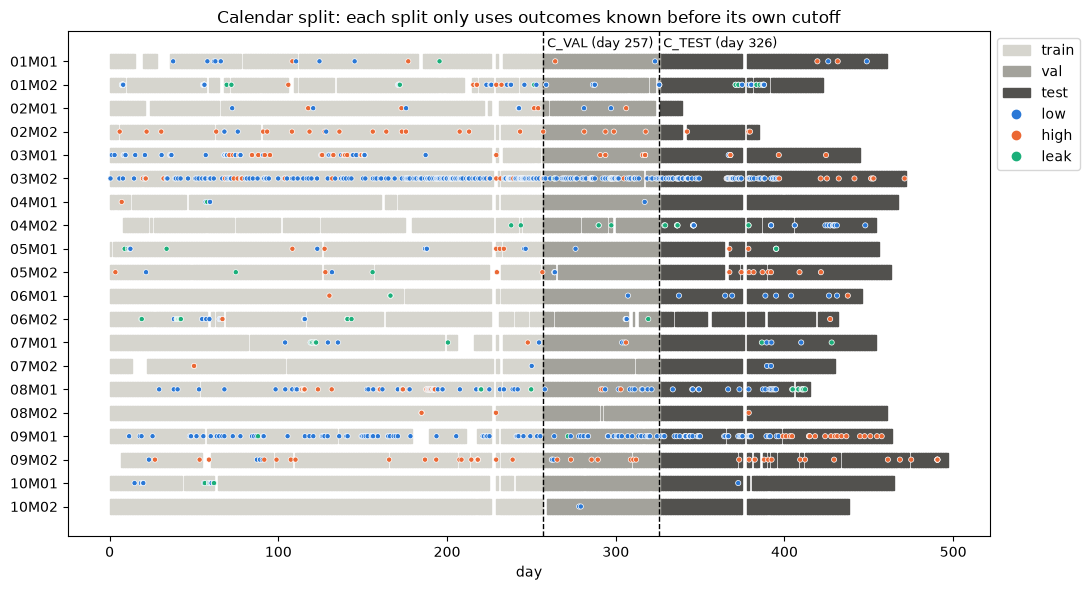

In [11]:
# 各機台的切分
days = windows[["tool", "t_last"]].assign(day=lambda d: (d.t_last - T0) // 86400).drop_duplicates(["tool", "day"])
days["split"] = np.select([days.t_last <= C_VAL, days.t_last <= C_TEST], ["train", "val"], "test")
shade = {"train": "#d6d5ce", "val": "#a3a29b", "test": "#52514e"}
inc = ep[ep.event != "censored"]

fig, ax = plt.subplots(figsize=(11, 6))
for i, tool in enumerate(tools[::-1]):
    for sp, g in days[days.tool == tool].groupby("split"):
        ax.broken_barh([(d, 1) for d in g.day], (i - 0.3, 0.6), color=shade[sp])
    f = inc[inc.tool == tool]
    ax.scatter((f.end - T0) / 86400, [i] * len(f), c=f.event.map(FAULT_COLORS), s=14, zorder=3, edgecolor="white", lw=0.5)
for c, name in [(C_VAL, "C_VAL"), (C_TEST, "C_TEST")]:
    x = (c - T0) / 86400
    ax.axvline(x, color="black", ls="--", lw=1)
    ax.text(x, len(tools) - 0.4, f" {name} (day {x:.0f})", fontsize=9)
ax.set_yticks(range(len(tools)), tools[::-1])
ax.set_xlabel("day")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in shade.values()] + \
          [plt.Line2D([], [], marker="o", ls="", color=c) for c in FAULT_COLORS.values()]
ax.legend(handles, list(shade) + list(FAULT_COLORS), loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Calendar split: each split only uses outcomes known before its own cutoff")
plt.tight_layout()
fig.savefig(os.path.join(OUT_DIR, "split_timeline.png"), dpi=150)
plt.show()

## 7. 存檔

In [12]:
windows[["tool", "episode_id", "win", "win_idx", "t_first", "t_last"] + SEQ_COLS].to_parquet(
    os.path.join(PROCESSED_DIR, "windows.parquet"), index=False)

LM_COLS = ["tool", "episode_id", "win", "win_idx", "t", "ep_end", "split", "residual_h", "event", "time_idx",
           "usable", "sample", "prev_type", "elapsed_h", "inc_7d", "inc_30d", "inc_30d_low", "inc_30d_high", "inc_30d_leak"]
lm[LM_COLS].to_parquet(os.path.join(PROCESSED_DIR, "landmarks.parquet"), index=False)

for f in ["windows.parquet", "landmarks.parquet"]:
    print(f, f"{os.path.getsize(os.path.join(PROCESSED_DIR, f)) / 1e6:.0f} MB")

windows.parquet 301 MB
landmarks.parquet 27 MB


## 結論

| 項目 | 結果 |
|---|---|
| 時間窗 | 82M 筆 4 秒資料 → 1,295,233 個 5 分鐘窗 × 52 個 window-level sensor 特徵 |
| 切分 | C_VAL = 第 257 天、C_TEST = 第 326 天（所有機台共用） |
| 樣本 | 每個窗 = 一個預測時間點；可用 1,294,973 個，抽 8% → train 61,460／val 15,385／test 26,252 |
| 標籤 | 7 天內下一次事故的時間（16 個時間格）與類型；模型將下一次 fault type 作為多類別事件輸出。三個 split 的截尾比例都在 72%～74%，test 的壓力過高比較多（9.9% vs train 7.3%） |
| 事故歷史 | 前一次事故類型、episode 已經過多久、過去 7／30 天事故次數（含各類型） |

